# Caso 06: AulaViva — Cursos online: ¿Qué alumno se queda?
## Día 3 (Mañana): La Primera Grieta — La Finalización por Canal y la Huella de la Intención

**Objetivos del Día 3:**
1. **Abrir la primera grieta en el relato de Growth (Acto 2 — Aprendizaje):**
   - Calcular qué proporción de las matrículas terminan los alumnos de cada canal (`SUM(CASE WHEN completado THEN 1 ELSE 0 END) * 100.0 / COUNT(*)`).
   - Contrastar la **media global engañosa (~23,3 %)** con la realidad desagregada por canal (`cupon` **9,0 %** frente a `referido` **44,0 %** y `empresas` **52,1 %**).
2. **El Cubo Agujereado y el Descarte de la Explicación Inocente:**
   - Antes de hablar de «baja intención», intentar tumbar el hallazgo con la hipótesis aburrida: *¿será que los alumnos del cupón simplemente se matriculan en menos cursos?*
   - Comprobar que todos los canales se matriculan prácticamente igual (**~6,2 cursos por alumno**), pero el alumno del cupón no termina casi ninguno (**0,56 cursos terminados por alumno** vs **2,72** en referido).
3. **Tres Ventanas a una Causa Invisible (La Intención del Alumno):**
   - Aunque ninguna columna se llame `intencion`, demostrar que tres señales independientes de compromiso (**1. Tasa de finalización**, **2. Minutos vistos por matrícula** y **3. Avance medio `%`**) ordenan a los cinco canales exactamente igual.
4. **Solidez Muestral (¿Es real o es ruido?):**
   - Acompañar cada porcentaje de su denominador (`93.905` matrículas en cupón y `29.705` en referido) para demostrar que una brecha de 35 puntos porcentuales sobre decenas de miles de casos es una señal rotunda.


In [1]:
import pandas as pd
import numpy as np
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb
import os

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

CLEAN_DIR = os.path.join('data', 'clean')
REPORTS_DIR = 'reports'
os.makedirs(REPORTS_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'Segoe UI'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

con = duckdb.connect()
for nombre in ['canales', 'campanas', 'usuarios', 'suscripciones', 'pagos', 'matriculas', 'cursos']:
    pq_path = os.path.join(CLEAN_DIR, f"{nombre}.parquet").replace("\\", "/")
    con.execute(f"CREATE OR REPLACE VIEW {nombre} AS SELECT * FROM '{pq_path}'")

print("Vistas SQL registradas en DuckDB correctamente.")


Vistas SQL registradas en DuckDB correctamente.


### 1. La Media que Engaña vs. La Tasa de Finalización por Canal (con su Muestra)
Si miramos la plataforma sin desagregar, la tasa de finalización global es del **23,3 %** («no está tan mal», diría Growth). Pero al abrir esa media por canal de captación, el ranking de altas se invierte de arriba abajo: el canal número uno en altas (`cupon`) es el último en aprendizaje.


In [2]:
q_media_global = """
SELECT
    COUNT(*) AS total_matriculas,
    SUM(CASE WHEN completado THEN 1 ELSE 0 END) AS total_completadas,
    ROUND(100.0 * SUM(CASE WHEN completado THEN 1 ELSE 0 END) / COUNT(*), 2) AS tasa_finalizacion_global_pct
FROM matriculas
"""
print("=== 1A. LA MEDIA GLOBAL QUE ENGAÑA ===")
display(con.execute(q_media_global).df())

q_finalizacion_canal = """
SELECT
    u.canal,
    COUNT(DISTINCT u.usuario_id) AS alumnos_con_matricula,
    COUNT(m.matricula_id) AS n_matriculas,
    SUM(CASE WHEN m.completado THEN 1 ELSE 0 END) AS matriculas_completadas,
    ROUND(100.0 * SUM(CASE WHEN m.completado THEN 1 ELSE 0 END) / COUNT(m.matricula_id), 2) AS tasa_finalizacion_pct
FROM matriculas m
JOIN usuarios u ON m.usuario_id = u.usuario_id
GROUP BY u.canal
ORDER BY tasa_finalizacion_pct ASC
"""
print("\n=== 1B. DESAGREGACIÓN POR CANAL: LA PRIMERA GRIETA (con tamaño de muestra) ===")
df_finalizacion = con.execute(q_finalizacion_canal).df()
display(df_finalizacion)


=== 1A. LA MEDIA GLOBAL QUE ENGAÑA ===


,total_matriculas,total_completadas,tasa_finalizacion_global_pct
0,247654,57755.0,23.32



=== 1B. DESAGREGACIÓN POR CANAL: LA PRIMERA GRIETA (con tamaño de muestra) ===


,canal,alumnos_con_matricula,n_matriculas,matriculas_completadas,tasa_finalizacion_pct
0,cupon,15200,93905,8465.0,9.01
1,anuncios,9600,59714,13184.0,22.08
2,seo,8000,49419,15260.0,30.88
3,referido,4800,29705,13080.0,44.03
4,empresas,2400,14911,7766.0,52.08


### 2. Tumbar la Explicación Inocente: ¿Se Matriculan Menos los Alumnos del Cupón?
Ante un **9,0 %** de finalización en el cupón frente a un **44,0 %** en el referido, un analista con oficio intenta primero tumbar su propia sospecha: *¿será que los alumnos del cupón apenas se apuntan a cursos?*
Cruzamos todas las altas (`usuarios`) con `matriculas` mediante CTEs para calcular cuántos cursos inicia de media un alumno de cada canal y cuántos termina realmente.


In [3]:
q_matriculas_por_alumno = """
WITH altas AS (
    SELECT
        canal,
        COUNT(*) AS total_alumnos
    FROM usuarios
    GROUP BY canal
),
aprendizaje AS (
    SELECT
        u.canal,
        COUNT(m.matricula_id) AS total_matriculas,
        SUM(CASE WHEN m.completado THEN 1 ELSE 0 END) AS total_completadas,
        COUNT(DISTINCT CASE WHEN m.completado THEN u.usuario_id END) AS alumnos_que_terminan_alguno
    FROM usuarios u
    LEFT JOIN matriculas m ON u.usuario_id = m.usuario_id
    GROUP BY u.canal
)
SELECT
    a.canal,
    a.total_alumnos,
    ap.total_matriculas,
    ROUND(1.0 * ap.total_matriculas / a.total_alumnos, 2) AS matriculas_por_alumno,
    ROUND(1.0 * ap.total_completadas / a.total_alumnos, 2) AS cursos_terminados_por_alumno,
    ROUND(100.0 * ap.total_completadas / ap.total_matriculas, 1) AS tasa_finalizacion_matriculas_pct,
    ROUND(100.0 * ap.alumnos_que_terminan_alguno / a.total_alumnos, 1) AS pct_alumnos_terminan_al_menos_1
FROM altas a
JOIN aprendizaje ap ON a.canal = ap.canal
ORDER BY tasa_finalizacion_matriculas_pct ASC
"""
df_mat_alumno = con.execute(q_matriculas_por_alumno).df()
df_mat_alumno


,canal,total_alumnos,total_matriculas,matriculas_por_alumno,cursos_terminados_por_alumno,tasa_finalizacion_matriculas_pct,pct_alumnos_terminan_al_menos_1
0,cupon,15200,93905,6.18,0.56,9.0,42.7
1,anuncios,9600,59714,6.22,1.37,22.1,75.3
2,seo,8000,49419,6.18,1.91,30.9,86.5
3,referido,4800,29705,6.19,2.73,44.0,94.8
4,empresas,2400,14911,6.21,3.24,52.1,96.3


**Veredicto sobre la hipótesis inocente:**
* Todos los canales se matriculan exactamente igual: **entre `6,18` y `6,22` cursos por alumno** (`6,18` en cupón, `6,19` en referido, `6,22` en empresas).
* La diferencia no está en apuntarse, sino en **terminar**: el alumno del cupón se apunta a `6,18` cursos y solo acaba **`0,56` cursos de media**, mientras que el del referido acaba **`2,72` cursos** (casi 5 veces más) y el de empresas **`3,24` cursos**.


### 3. Tres Ventanas a una Causa Invisible: La Huella de la Intención
En ninguna tabla existe una columna llamada `intencion_del_alumno`. Pero podemos medir tres consecuencias independientes del compromiso en el LMS (excluyendo los datos imposibles marcados el Día 2: `minutos_validos = TRUE` y `pct_valido = TRUE`):
1. **¿Termina cursos?** $\rightarrow$ `tasa_finalizacion_pct`
2. **¿Se implica viendo clases?** $\rightarrow$ `minutos_por_matricula` (`AVG(minutos_vistos)`)
3. **¿Avanza en el temario?** $\rightarrow$ `avance_medio_pct` (`AVG(pct_completado)`)


In [4]:
q_tres_ventanas = """
SELECT
    u.canal,
    COUNT(m.matricula_id) AS n_matriculas_muestra,
    ROUND(100.0 * SUM(CASE WHEN m.completado THEN 1 ELSE 0 END) / COUNT(m.matricula_id), 1) AS finalizacion_pct,
    ROUND(AVG(CASE WHEN m.minutos_validos THEN m.minutos_vistos END), 0) AS minutos_por_matricula,
    ROUND(AVG(CASE WHEN m.pct_valido THEN m.pct_completado END), 1) AS avance_medio_pct
FROM matriculas m
JOIN usuarios u ON m.usuario_id = u.usuario_id
GROUP BY u.canal
ORDER BY finalizacion_pct ASC
"""
df_tres_ventanas = con.execute(q_tres_ventanas).df()
df_tres_ventanas


,canal,n_matriculas_muestra,finalizacion_pct,minutos_por_matricula,avance_medio_pct
0,cupon,93905,9.0,140.0,40.0
1,anuncios,59714,22.1,165.0,47.2
2,seo,49419,30.9,181.0,51.9
3,referido,29705,44.0,206.0,59.2
4,empresas,14911,52.1,221.0,63.8


### 4. Visualizaciones de Diagnóstico (Guardadas en `reports/`)
Generamos dos gráficos limpios (empezando siempre los ejes en cero y mostrando el tamaño de muestra `n` junto a cada porcentaje) para documentar el hallazgo del Día 3:
1. `reports/dia_03_finalizacion_por_canal.png`: La primera grieta frente a la media global engañosa.
2. `reports/dia_03_tres_ventanas_intencion.png`: Las tres medidas independientes de compromiso que revelan la intención del alumno.


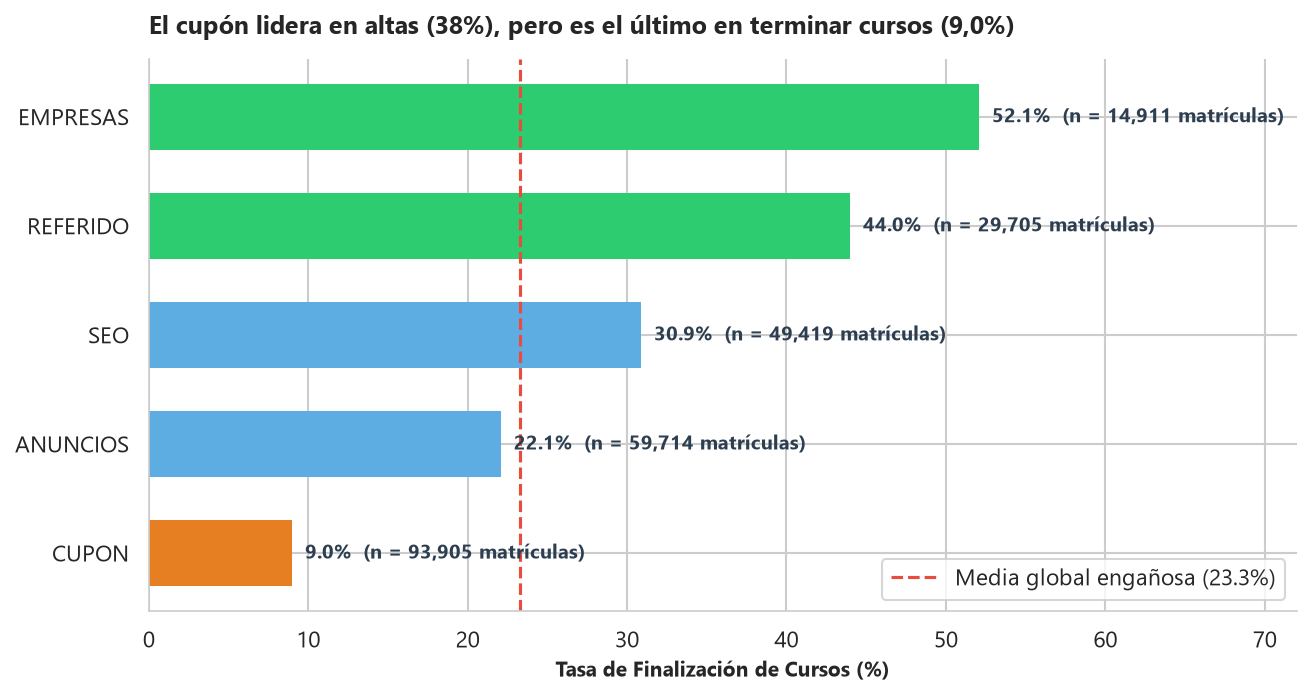

Gráfico guardado en: reports\dia_03_finalizacion_por_canal.png


In [5]:
# Gráfico 1: Tasa de finalización por canal + muestra + media global
fig, ax = plt.subplots(figsize=(9, 4.8), dpi=150)

df_plot = df_tres_ventanas.sort_values('finalizacion_pct', ascending=True).reset_index(drop=True)
colores = ['#e67e22' if c == 'cupon' else ('#2ecc71' if c in ['referido', 'empresas'] else '#5dade2') for c in df_plot['canal']]

bars = ax.barh(df_plot['canal'].str.upper(), df_plot['finalizacion_pct'], color=colores, height=0.6, edgecolor='none')

media_global = 23.30
ax.axvline(media_global, color='#e74c3c', linestyle='--', linewidth=1.5, label=f'Media global engañosa ({media_global:.1f}%)')

for bar, (_, row) in zip(bars, df_plot.iterrows()):
    w = bar.get_width()
    ax.text(
        w + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{row['finalizacion_pct']:.1f}%  (n = {int(row['n_matriculas_muestra']):,} matrículas)",
        va='center', ha='left', fontsize=9.5, fontweight='bold', color='#2c3e50'
    )

ax.set_xlim(0, 72)
ax.set_xlabel('Tasa de Finalización de Cursos (%)', fontsize=10, fontweight='bold')
ax.set_title('El cupón lidera en altas (38%), pero es el último en terminar cursos (9,0%)', fontsize=12, fontweight='bold', pad=12, loc='left')
ax.legend(loc='lower right', frameon=True)
sns.despine(top=True, right=True)
plt.tight_layout()
out_path_1 = os.path.join(REPORTS_DIR, 'dia_03_finalizacion_por_canal.png')
plt.savefig(out_path_1, dpi=150)
plt.show()
print("Gráfico guardado en:", out_path_1)


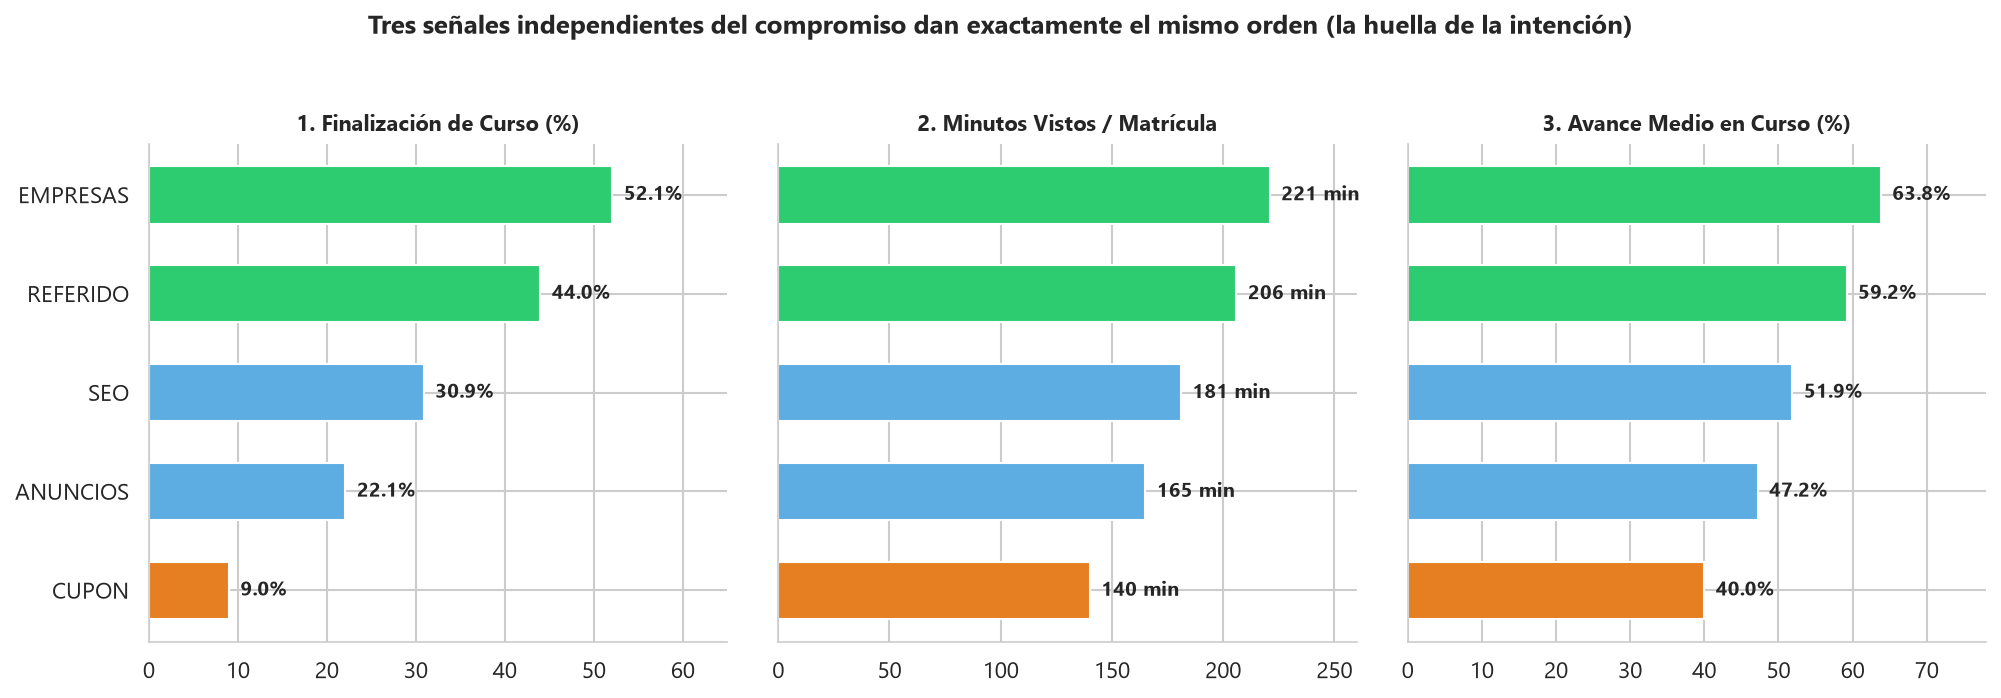

Gráfico guardado en: reports\dia_03_tres_ventanas_intencion.png


In [6]:
# Gráfico 2: Las 3 ventanas de la intención (Finalización, Minutos/Matrícula, Avance Medio)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.5), dpi=150, sharey=True)

metricas = [
    ('finalizacion_pct', '1. Finalización de Curso (%)', '%', 65),
    ('minutos_por_matricula', '2. Minutos Vistos / Matrícula', ' min', 260),
    ('avance_medio_pct', '3. Avance Medio en Curso (%)', '%', 78)
]

for ax, (col, titulo, sufijo, xlim_max) in zip(axes, metricas):
    bars = ax.barh(df_plot['canal'].str.upper(), df_plot[col], color=colores, height=0.58)
    ax.set_xlim(0, xlim_max)
    ax.set_title(titulo, fontsize=10.5, fontweight='bold')
    sns.despine(ax=ax, top=True, right=True)
    for bar in bars:
        w = bar.get_width()
        fmt = f"{w:.0f}{sufijo}" if col == 'minutos_por_matricula' else f"{w:.1f}{sufijo}"
        ax.text(w + xlim_max * 0.02, bar.get_y() + bar.get_height()/2, fmt, va='center', ha='left', fontsize=9.5, fontweight='bold')

fig.suptitle('Tres señales independientes del compromiso dan exactamente el mismo orden (la huella de la intención)', fontsize=12.5, fontweight='bold', y=1.03)
plt.tight_layout()
out_path_2 = os.path.join(REPORTS_DIR, 'dia_03_tres_ventanas_intencion.png')
plt.savefig(out_path_2, dpi=150, bbox_inches='tight')
plt.show()
print("Gráfico guardado en:", out_path_2)


### Conclusiones al cerrar el Día 3 (La Mitad de la Respuesta)
1. **La primera grieta es rotunda y estadísticamente sólida:**
   - Sobre **`93.905` matrículas**, los alumnos del **cupón** solo terminan el **`9,0 %`** de los cursos que empiezan, frente al **`44,0 %`** del **referido** (`29.705` matrículas) y el **`52,1 %`** de **empresas** (`14.929` matrículas).
2. **Descartada la explicación inocente (cantidad de matrículas):**
   - Los alumnos del cupón no se matriculan menos (`6,18` cursos/alumno vs `6,19` en referido): se apuntan a seis cursos y abandonan casi todos (`0,56` cursos completados por alumno).
3. **Tres señales independientes revelan la intención del alumno:**
   - **Finalización:** `9,0 %` en cupón vs `44,0 %` en referido.
   - **Minutos vistos por matrícula:** `140 min` en cupón vs `206 min` en referido.
   - **Avance medio:** `40,0 %` en cupón vs `59,0 %` en referido.
4. **Por qué hoy solo tenemos media respuesta (el encargo de Nuria para el Día 4):**
   - Ya sabemos que los alumnos del cupón no aprenden. Pero el presupuesto no se decide por matrículas terminadas, sino por dinero. Mañana (Día 4) conectaremos esta grieta con la **tasa de renovación**, el **LTV por alumno**, la **cuota de valor por canal** y el **control de confusión por categoría** para responder a Paula Rivas.
